In [1]:
import mne
from anlffr.helper import biosemi2mne as bs
from anlffr.preproc import find_blinks
from matplotlib import pyplot as plt
from mne import compute_proj_epochs
from mne import concatenate_epochs
import pylab as pl
import numpy as np
import os
import fnmatch
from scipy.fft import fft
from scipy.signal import find_peaks
import gc

In [2]:
NH_subjs = ['SP003', 'SP004', 'SP005', 'SP006', 'SP007', 'SP008', 'SP009', 'SP010']
HL_subjs = ['HL001', 'HL002', 'HL004', 'HL005', 'HL007', 'HL008', 'HL010', 'HL011', 
            'HL013', 'HL017', 'HL018', 'HL021', 'HL023', 'HL025', 'HL029', 'HL036'] #yet to add HL036 to the analysis and figures below
subjs = NH_subjs + HL_subjs

# subjs = ['SP010', 'HL029']

## RUN for all subjects

In [3]:
# fpath = "/Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Scene_Analysis/"
# resultsdir = 'results/'
# subj = 'HL002'
# epoch = []

# bdfs = fnmatch.filter(os.listdir(fpath), subj + '_SceneAnalysis.bdf')
# print(bdfs)
# for k, bdf in enumerate(bdfs):
#     bdf_fullpath = os.path.join(fpath, bdf) 
#     raw, eves = bs.importbdf(bdf_fullpath, hptsname='biosemi10_20.hpts')
#     raw.notch_filter(np.arange(60, 241, 60), filter_length='auto', fir_design='firwin')
#     raw.filter(1, 40)

#     blinks = find_blinks(raw, ch_name=['Fp1'])

#     if subj in ['SP004' 'HL007', 'HL025'] :
#         if k == 0:
#             epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
#                                         reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
#             blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=2)
#         raw.add_proj(blink_proj)
#         raw.apply_proj()

#     elif subj in ['HL004', 'HL002']:
#         if k == 0:
#             epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
#                                         reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
#             blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=4)
#         raw.add_proj(blink_proj)
#         raw.del_proj(1)
#         raw.del_proj(2)
#         raw.apply_proj()
            
#     else:
#         if k == 0:
#             epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
#                                         reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
#             blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=3)
#         raw.add_proj(blink_proj)
#         raw.del_proj(1)
#         raw.apply_proj()


#     epochs = mne.Epochs(raw, eves, event_id=1, baseline=(0.75, 1), proj=True,
#                         tmin=0.75, tmax=2, reject=dict(eeg=200e-6))
    
#     epoch += [epochs, ]

# epoch_coherent = concatenate_epochs(epoch)
# print(f'Finished running {subj}')

# raw.plot_projs_topomap()

In [ ]:
fpath = "/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/"
resultsdir = 'results/'
channels_to_drop = ['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']
# subjs = ['HL036']
epoch = []

for subj in subjs:
    print(f'Running {subj}')
    fpath = "/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/"
    resultsdir = 'results/'
    epoch = []

    bdfs = fnmatch.filter(os.listdir(fpath), subj + '_SceneAnalysis.bdf')
    print(bdfs)
    for k, bdf in enumerate(bdfs):
        bdf_fullpath = os.path.join(fpath, bdf) 
        raw, eves = bs.importbdf(bdf_fullpath, hptsname='biosemi10_20.hpts')
        raw.notch_filter(np.arange(60, 241, 60), filter_length='auto', fir_design='firwin')
        raw.filter(0.2, 70)

        blinks = find_blinks(raw, ch_name=['Fp1'])

        if subj in ['SP004', 'HL007', 'HL025', 'SP008', 'HL001', 'HL017']:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                            reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=2)
            raw.add_proj(blink_proj)
            raw.apply_proj()

        elif subj in ['HL004', 'HL002', 'HL007']:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                            reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=4)
            raw.add_proj(blink_proj)
            raw.del_proj(1)
            raw.del_proj(2)
            raw.apply_proj()
                
        else:
            if k == 0:
                epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                                            reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
                blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=3)
            raw.add_proj(blink_proj)
            raw.del_proj(1)
            raw.apply_proj()

        epochs = mne.Epochs(raw, eves, event_id=1, baseline=(-0.25, 0), proj=True,
                            tmin=-0.25, tmax=2.2, reject=dict(eeg=200e-6))
        
        epoch += [epochs, ]

    epoch_coherent = concatenate_epochs(epoch)
    print(f"\033[1;31mFinished running {subj}\033[0m") 

    raw.plot_projs_topomap()

    evoked = epoch_coherent.average()
    evoked.save(fpath + resultsdir + subj + '_SceneAnalysis-ave.fif',overwrite=True)

    freqs = np.arange(5., 70., 1.)
    n_cycles = freqs * 0.4

    power_Fz = epoch_coherent.compute_tfr(method="multitaper", freqs=freqs, picks=[30], return_itc=False, n_cycles=n_cycles) #FC5, CP5, C3, T7
    power_Cz = epoch_coherent.compute_tfr(method="multitaper", freqs=freqs, picks=[31], return_itc=False, n_cycles=n_cycles) #FC6, CP6, C4, T8

    power_Fz.save(fpath + resultsdir + subj + '_SceneAnalysis_completeTrial_Fz-tfr.h5', overwrite=True)
    power_Cz.save(fpath + resultsdir + subj + '_SceneAnalysis_completeTrial_Cz-tfr.h5', overwrite=True)

    del raw, epochs, epoch_coherent, evoked
    del power_Fz, power_Cz
    gc.collect()
    print(f'Finished saving {subj}')

Running SP003
['SP003_SceneAnalysis.bdf']
Extracting EDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/SP003_SceneAnalysis.bdf...


BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Trigger channel Status has a non-zero initial value of 130816 (consider using initial_event=True to detect this event)
227 events found on stim channel Status
Event IDs: [  1 253]
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 108135 samples (6.600 s)



[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    3.3s


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.2 - 70 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.20
- Lower transition bandwidth: 0.20 Hz (-6 dB cutoff frequency: 0.10 Hz)
- Upper passband edge: 70.00 Hz
- Upper transition bandwidth: 17.50 Hz (-6 dB cutoff frequency: 78.75 Hz)
- Filter length: 270337 samples (16.500 s)



[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.5s


...

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.2 - 70 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.20
- Lower transition bandwidth: 0.20 Hz (-6 dB cutoff frequency: 0.10 Hz)
- Upper passband edge: 70.00 Hz
- Upper transition bandwidth: 17.50 Hz (-6 dB cutoff frequency: 78.75 Hz)
- Filter length: 270337 samples (16.500 s)



[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    2.8s


Setting up band-pass filter from 0.5 - 10 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.15 Hz (-6 dB cutoff frequency: 0.42 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 2.50 Hz (-6 dB cutoff frequency: 11.25 Hz)
- Filter length: 360449 samples (22.000 s)

Not setting metadata
51 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC5', 'FC6', 'Fp2']
    Rejecting  epoch based on EEG : ['FC6']
No channels 'grad' found. Skipping.
No channels 'mag' found. Skipping.
Adding projection: eeg-998--0.250-0.250-PCA-01 (exp var=68.8%)
Adding projection: eeg-998--0.250-0.250-PCA-02 (exp var=10.1%)
Adding projection

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s


SSP projectors applied...
Not setting metadata
238 matching events found
Applying baseline correction (mode: mean)
Created an SSP operator (subspace dimension = 2)
2 projection items activated
Using data from preloaded Raw for 238 events and 40142 original time points ...
    Rejecting  epoch based on EEG : ['Fp1', 'F7', 'FC5', 'CP6', 'T8', 'FC6', 'F8', 'Fp2']
    Rejecting  epoch based on EEG : ['Fp1', 'FC6', 'Fp2']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['FC2']
    Rejecting  epoch based on EEG : ['Fp1', 'AF3', 'T7', 'P8', 'CP6', 'T8', 'FC6', 'FC2', 'F4', 'F8', 'AF4', 'Fp2']
    Rejecting  epoch based on EEG : ['Fp1', 'F7', 'FC5', 'CP6', 'T8', 'FC6', 'F8', 'Fp2']
    Rejecting  epoch based on EEG : ['CP6', 'T8', 'FC6', 'FC2', 'F8']
    Rejecting  epoch based on EEG : ['FC6']
    Rejecting  epoch based on EEG : ['Fp1', 'Fp2']
    Rejecting  epoch based on EEG : ['Fp1', 'F7', 'P8', 'CP6', 'C4', 'T8', '

## Evoked Response

Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/SP003_SceneAnalysis-ave.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -250.00 ...    2200.01 ms (1)
        0 CTF compensation matrices available
        nave = 223 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.25, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/SP003_SceneAnalysis-ave.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_21112/1029895354.py:22: RuntimeWarning: filter_length (216269) is longer than the signal (40142), distortion is likely. Reduce filter length or filter a longer signal.
  evokeds_NH = [mne.read_evokeds(f)[0].copy().filter(0.25, 20) for f in evoked_files_NH]


Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/SP004_SceneAnalysis-ave.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-02 (1 x 32) active
    Found the data of interest:
        t =    -250.00 ...    2200.01 ms (1)
        0 CTF compensation matrices available
        nave = 193 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.25, 0] s)
Setting up band-pass filter from 0.25 - 20 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.25
- Lower transition bandwidth: 0.25 Hz (-6 dB cutoff 

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.1s
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_21112/1029895354.py:22: RuntimeWarning: filter_length (216269) is longer than the signal (40142), distortion is likely. Reduce filter length or filter a longer signal.
  evokeds_NH = [mne.read_evokeds(f)[0].copy().filter(0.25, 20) for f in evoked_files_NH]


Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/SP005_SceneAnalysis-ave.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -250.00 ...    2200.01 ms (1)
        0 CTF compensation matrices available
        nave = 190 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.25, 0] s)
Setting up band-pass filter from 0.25 - 20 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.25
- Lower transition bandwidth: 0.25 Hz (-6 dB cutoff 

...

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.1s
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_21112/1029895354.py:25: RuntimeWarning: filter_length (216269) is longer than the signal (40142), distortion is likely. Reduce filter length or filter a longer signal.
  evokeds_HL = [mne.read_evokeds(f)[0].copy().filter(0.25, 20) for f in evoked_files_HL]


Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/HL029_SceneAnalysis-ave.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -250.00 ...    2200.01 ms (1)
        0 CTF compensation matrices available
        nave = 217 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.25, 0] s)
Setting up band-pass filter from 0.25 - 20 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.25
- Lower transition bandwidth: 0.25 Hz (-6 dB cutoff 

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.1s
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_21112/1029895354.py:25: RuntimeWarning: filter_length (216269) is longer than the signal (40142), distortion is likely. Reduce filter length or filter a longer signal.
  evokeds_HL = [mne.read_evokeds(f)[0].copy().filter(0.25, 20) for f in evoked_files_HL]


Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/HL036_SceneAnalysis-ave.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -250.00 ...    2200.01 ms (1)
        0 CTF compensation matrices available
        nave = 179 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.25, 0] s)
Setting up band-pass filter from 0.25 - 20 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.25
- Lower transition bandwidth: 0.25 Hz (-6 dB cutoff 

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.1s
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_21112/1029895354.py:25: RuntimeWarning: filter_length (216269) is longer than the signal (40142), distortion is likely. Reduce filter length or filter a longer signal.
  evokeds_HL = [mne.read_evokeds(f)[0].copy().filter(0.25, 20) for f in evoked_files_HL]
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.1s


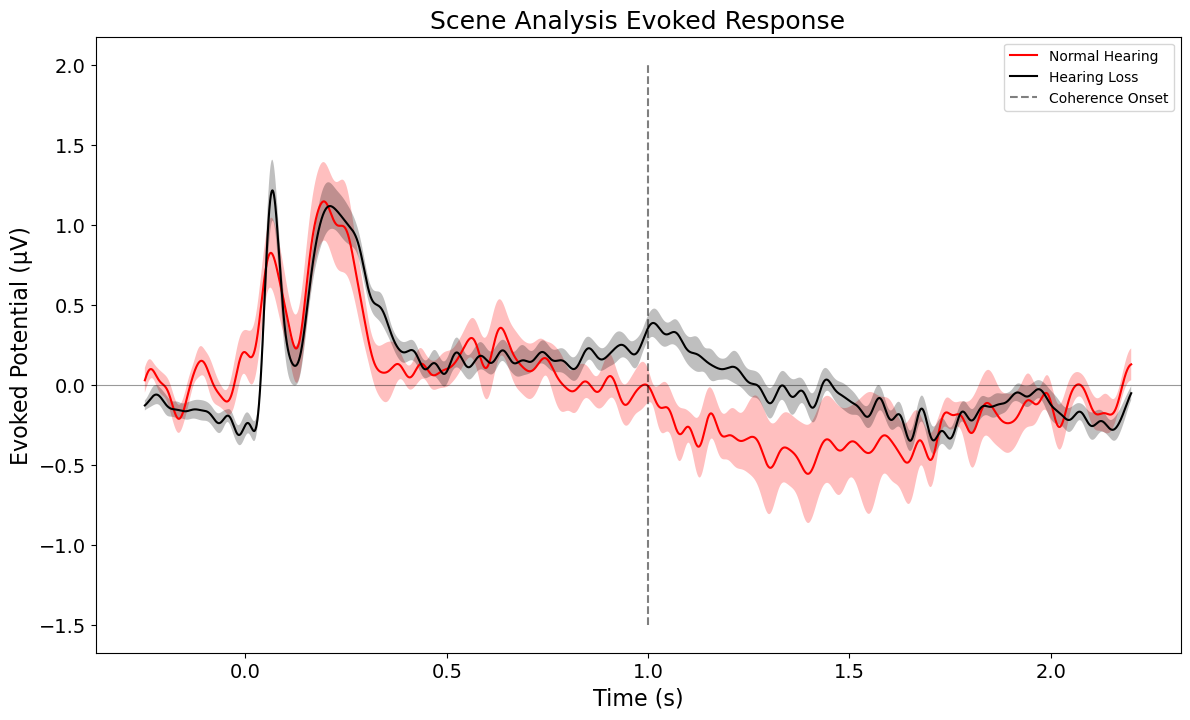

In [5]:
def evoked_avg(channels, x):
    sum = 0
    for i in channels:
        sum += x[i,]
        avg = sum / len(channels)
    return avg


evoked_NH = [f'{subject_id}_SceneAnalysis-ave.fif' for subject_id in NH_subjs]

base_path = "/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/"

evoked_1_NH = [base_path + filename for filename in evoked_NH]


evoked1 = mne.read_evokeds(evoked_1_NH[0])[0]
time = evoked1.times



evoked_files_NH = [f"{base_path}{sid}_SceneAnalysis-ave.fif" for sid in NH_subjs]
evokeds_NH = [mne.read_evokeds(f)[0].copy().filter(0.25, 20) for f in evoked_files_NH]

evoked_files_HL = [f"{base_path}{sid}_SceneAnalysis-ave.fif" for sid in HL_subjs]
evokeds_HL = [mne.read_evokeds(f)[0].copy().filter(0.25, 20) for f in evoked_files_HL]

chan_idx = [6, 5, 9, 7, 23, 24, 20, 22]

# sum_x = 0
# sum_x = evoked_avg([6, 5, 9, 7, 23, 24, 20, 22], x_NH)

# fig, ax = plt.subplots(figsize=(12, 5))
# ax.plot(time, sum_x/4, linewidth=1.5, color='red', label='Evoked Lead') 

# ax.set_xlabel('Time (s)', fontsize=16)
# ax.set_ylabel('Evoked Potential(µV)', fontsize=16)

# ax.tick_params(axis='both', labelsize=14)
# # plt.savefig(foldername+'Evoked_NH_newest.pdf', format='pdf')
# plt.show()

subj_chanavg_NH = np.stack([
    evk.data[chan_idx, :].mean(axis=0) * 1e6  # convert V → µV
    for evk in evokeds_NH
])

subj_chanavg_HL = np.stack([
    evk.data[chan_idx, :].mean(axis=0) * 1e6  # convert V → µV
    for evk in evokeds_HL
])

grand_mean_HL = subj_chanavg_HL.mean(axis=0)
n_HL = subj_chanavg_HL.shape[0]
sem_HL = subj_chanavg_HL.std(axis=0, ddof=1) / np.sqrt(n_HL)

# --- grand mean and SEM across subjects ---
grand_mean_NH = subj_chanavg_NH.mean(axis=0)
n_NH = subj_chanavg_NH.shape[0]
sem_NH = subj_chanavg_NH.std(axis=0, ddof=1) / np.sqrt(n_NH)

# --- plot with SEM ribbon ---
fig, ax = plt.subplots(figsize=(14, 8))
ax.plot(time, grand_mean_NH, linewidth=1.5, color='red', label='Normal Hearing')

ax.plot(time, grand_mean_HL, linewidth=1.5, color='black', label='Hearing Loss')

ax.fill_between(time, grand_mean_NH-sem_NH, grand_mean_NH+sem_NH, color='red', alpha=0.25, edgecolor='none')
ax.fill_between(time, grand_mean_HL-sem_HL, grand_mean_HL+sem_HL, color='black', alpha=0.25, edgecolor='none')

ax.vlines(1, -1.5, 2, colors='k', linestyles='dashed', alpha=0.5, label='Coherence Onset')

ax.set_title('Scene Analysis Evoked Response', fontsize=18)
ax.set_xlabel('Time (s)', fontsize=16)
ax.set_ylabel('Evoked Potential (µV)', fontsize=16)
ax.tick_params(axis='both', labelsize=14)
ax.axhline(0, linewidth=0.8, color='k', alpha=0.4)
ax.legend()
plt.show()

## Evoked Response Results

In [13]:
# import numpy as np
# import matplotlib.pyplot as plt
# import mne

# def evoked_avg(channels, x):
#     """Average data across given channels."""
#     return np.mean(x[channels, :], axis=0)

# # List of .fif files for each subject
# evoked_NH_files = [f'{base_path}{subject_id}_SceneAnalysis-ave.fif' for subject_id in NH_subjs]

# # Read evokeds for each subject
# evoked_NH = [mne.read_evokeds(fname)[0] for fname in evoked_NH_files]

# # Filter each subject’s data
# for evk in evoked_NH:
#     evk.filter(0.25, 20)

# # Extract data from desired channels for each subject
# channels_of_interest = [6, 5, 9, 7, 23, 24, 20, 22]
# all_subject_data = []

# for evk in evoked_NH:
#     x = evk.data * 1e6  # convert to µV
#     chan_avg = evoked_avg(channels_of_interest, x)
#     all_subject_data.append(chan_avg)

# all_subject_data = np.array(all_subject_data)  # shape: (n_subjects, n_times)

# # Compute mean and std across subjects
# mean_evoked = np.mean(all_subject_data, axis=0)
# std_evoked = np.std(all_subject_data, axis=0)

# # Time vector from first evoked
# time = evoked_NH[0].times

# # Plot
# fig, ax = plt.subplots(figsize=(12, 5))
# ax.plot(time, mean_evoked, linewidth=1.5, color='red', label='Evoked Lead')
# ax.fill_between(time, mean_evoked - std_evoked, mean_evoked + std_evoked,
#                 color='red', alpha=0.3, label='±1 SD')

# ax.set_xlabel('Time (s)', fontsize=14)
# ax.set_ylabel('Amplitude (µV)', fontsize=14)
# ax.legend()
# plt.show()


In [14]:
# evoked_HL = [f'{subject_id}_SceneAnalysis-ave.fif' for subject_id in HL_subjs]

# base_path = "/Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Scene_Analysis/results/"

# evoked_1_HL = [base_path + filename for filename in evoked_HL]

# evoked_HL = [mne.read_evokeds(leads)[0] for leads in evoked_1_HL]

# evoked1 = mne.read_evokeds(evoked_1_HL[0])[0]
# time = evoked1.times

# average_evoked_lead_HL = mne.grand_average(evoked_HL)

# average_evoked_lead_HL.filter(0.25, 20)

# x_HL = average_evoked_lead_HL.data*1e6

# sum_x = 0
# sum_x = evoked_avg([6, 5, 9, 7, 23, 24, 20, 22], x_HL)
# # time = np.linspace(-0.25, 2, x_HL.shape[1])

# fig, ax = plt.subplots(figsize=(12, 5))
# ax.plot(time, sum_x/4, linewidth=1.5, color='red', label='Evoked Lead') 

# ax.set_xlabel('Time (s)', fontsize=16)
# ax.set_ylabel('Evoked Potential(µV)', fontsize=16)

# ax.tick_params(axis='both', labelsize=14)
# plt.show()

## Group Average Spectrogram

In [6]:
# Group Average Spectrogram

res_fpath = "/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/"

power_Fz_NH_files = [f'{subject_id}_SceneAnalysis_completeTrial_Fz-tfr.h5' for subject_id in NH_subjs]
power_Cz_NH_files = [f'{subject_id}_SceneAnalysis_completeTrial_Cz-tfr.h5' for subject_id in NH_subjs]

power_Fz_1_NH_ = [res_fpath + filename for filename in power_Fz_NH_files]
power_Cz_1_NH_ = [res_fpath + filename for filename in power_Cz_NH_files]

tfr_Fz_NH = [mne.time_frequency.read_tfrs(f)[0] for f in power_Fz_1_NH_]
tfr_Cz_NH = [mne.time_frequency.read_tfrs(f)[0] for f in power_Cz_1_NH_]

tfrs_avg_Fz_NH = [tfr.average() for tfr in tfr_Fz_NH]
tfrs_avg_Cz_NH = [tfr.average() for tfr in tfr_Cz_NH] 

# for i, tfr in enumerate(tfrs_avg_leftAC_NH):
#     print(f"Subject {i}: shape = {tfr.data.shape}, time len = {len(tfr.times)}")

# Find common time range
min_time = max(tfr.times[0] for tfr in tfrs_avg_Fz_NH)
max_time = min(tfr.times[-1] for tfr in tfrs_avg_Cz_NH)
max_time = min(max_time, 2.0)  # Ensure max_time does not exceed 2.0 seconds
print(f"Common time range: {min_time} to {max_time} seconds")

# # Crop all to this common window
tfrs_avg_Fz_NH = [tfr.copy().crop(tmin=min_time, tmax=max_time) for tfr in tfrs_avg_Fz_NH]
tfrs_avg_Cz_NH = [tfr.copy().crop(tmin=min_time, tmax=max_time) for tfr in tfrs_avg_Cz_NH]

tfr_Fz_NH = mne.grand_average(tfrs_avg_Fz_NH)
tfr_Cz_NH = mne.grand_average(tfrs_avg_Cz_NH)

Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/SP003_SceneAnalysis_completeTrial_Fz-tfr.h5 ...
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/SP004_SceneAnalysis_completeTrial_Fz-tfr.h5 ...
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/SP005_SceneAnalysis_completeTrial_Fz-tfr.h5 ...
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/SP006_SceneAnalysis_completeTrial_Fz-tfr.h5 ...
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE stu

In [7]:
# average_tfr_leftAC_NH = tfr_leftAC_NH.copy()
# sum_tfr_leftAC_NH = np.zeros(tfr_leftAC_NH.data.shape)  

# for i in range (len(tfr_leftAC_NH.ch_names)):
#     sum_tfr_leftAC_NH = tfr_leftAC_NH.data[i, :, :] + sum_tfr_leftAC_NH 
# average_tfr_leftAC_NH.data = sum_tfr_leftAC_NH / len(tfr_leftAC_NH.ch_names)

Applying baseline correction (mode: zscore)


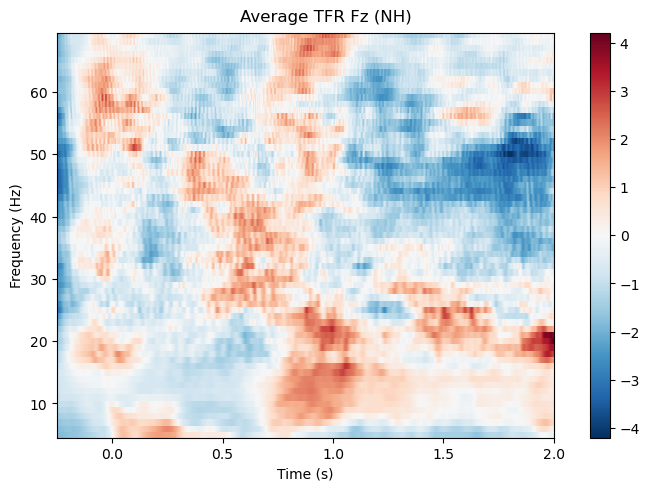

Applying baseline correction (mode: zscore)


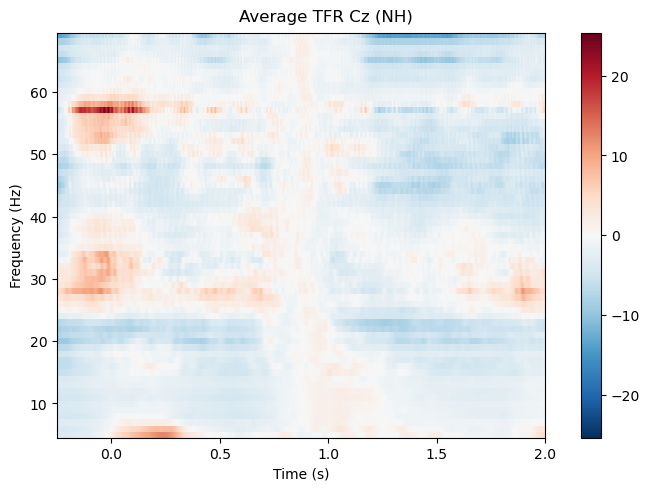

[<Figure size 640x480 with 2 Axes>]

In [8]:
# # Plot average spectrogram for Left AC condition
# tfr_leftAC_NH.plot(
#     picks='all',              # or specify a list of the 4 channels if you want
#     baseline=(0.75, 1),       # e.g., baseline correction from -0.5 to 0
#     mode='zscore',          # or 'zscore', 'mean', etc.
#     title='Average TFR - Left AC (NH)',
#     show=True
# )

# # Plot average spectrogram for Right AC condition
# tfr_rightAC_NH.plot(
#     picks='all',
#     baseline=(0.75, 1),
#     mode='zscore',
#     title='Average TFR - Right AC (NH)',
#     show=True
# )

tfr_Fz_NH.plot(
    picks="data", baseline=(-0.25, 1), mode="zscore",
    title="Average TFR Fz (NH)", show=True
)
tfr_Cz_NH.plot(
    picks="data", baseline=(0.75, 1), mode="zscore",
    title="Average TFR Cz (NH)", show=True
)

In [9]:
# Group Average Spectrogram

res_fpath = "/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/"

power_Fz_HL_files = [f'{subject_id}_SceneAnalysis_completeTrial_Fz-tfr.h5' for subject_id in HL_subjs]
power_Cz_HL_files = [f'{subject_id}_SceneAnalysis_completeTrial_Cz-tfr.h5' for subject_id in HL_subjs]

power_Fz_1_HL_ = [res_fpath + filename for filename in power_Fz_HL_files]
power_Cz_1_HL_ = [res_fpath + filename for filename in power_Cz_HL_files]

tfr_Fz_HL = [mne.time_frequency.read_tfrs(f)[0] for f in power_Fz_1_HL_]
tfr_Cz_HL = [mne.time_frequency.read_tfrs(f)[0] for f in power_Cz_1_HL_]

tfrs_avg_Fz_HL = [tfr.average() for tfr in tfr_Fz_HL]
tfrs_avg_Cz_HL = [tfr.average() for tfr in tfr_Cz_HL] 

# for i, tfr in enumerate(tfrs_avg_leftAC_NH):
#     print(f"Subject {i}: shape = {tfr.data.shape}, time len = {len(tfr.times)}")

# Find common time range
min_time = max(tfr.times[0] for tfr in tfrs_avg_Fz_HL)
max_time = min(tfr.times[-1] for tfr in tfrs_avg_Cz_HL)
max_time = min(max_time, 2.0)  # Ensure max_time does not exceed 2.0 seconds

# Crop all to this common window
tfrs_avg_Fz_HL = [tfr.copy().crop(tmin=min_time, tmax=max_time) for tfr in tfrs_avg_Fz_HL]
tfrs_avg_Cz_HL = [tfr.copy().crop(tmin=min_time, tmax=max_time) for tfr in tfrs_avg_Cz_HL]

tfr_Fz_HL = mne.grand_average(tfrs_avg_Fz_HL)
tfr_Cz_HL = mne.grand_average(tfrs_avg_Cz_HL)

Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/HL001_SceneAnalysis_completeTrial_Fz-tfr.h5 ...
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/HL002_SceneAnalysis_completeTrial_Fz-tfr.h5 ...
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/HL004_SceneAnalysis_completeTrial_Fz-tfr.h5 ...
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/SceneAnalysis_EEG/results/HL005_SceneAnalysis_completeTrial_Fz-tfr.h5 ...
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE stu

Applying baseline correction (mode: zscore)


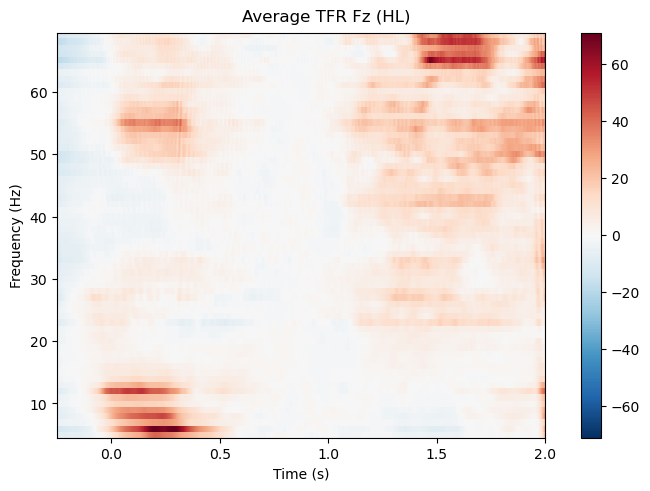

Applying baseline correction (mode: zscore)


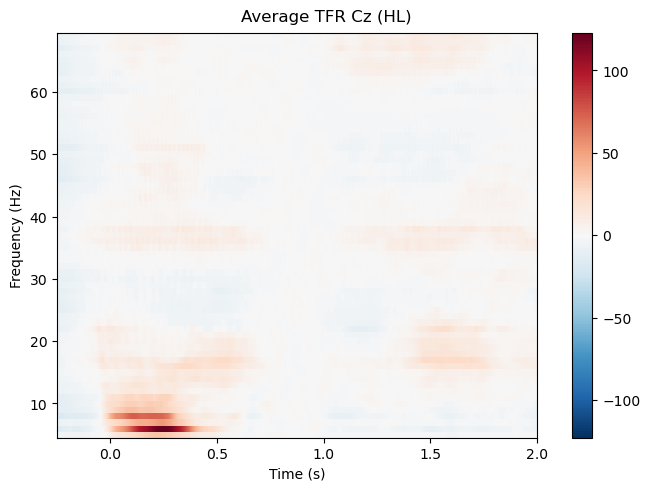

[<Figure size 640x480 with 2 Axes>]

In [10]:
tfr_Fz_HL.plot(
    picks="data", baseline=(0.75, 1), mode="zscore",
    title="Average TFR Fz (HL)", show=True
)
tfr_Cz_HL.plot(
    picks="data", baseline=(0.75, 1), mode="zscore",
    title="Average TFR Cz (HL)", show=True
)